# C06 – Xuất xứ hàng hóa theo ngành hàng và mức giá

**Câu hỏi Q4:** Trong cửa hàng tại TP.HCM, bao nhiêu hàng là "Made in Vietnam", xét theo ngành hàng (phần HS) và mức giá?

| Mã | Task | Dạng | Lý do chọn |
|---|---|---|---|
| C06A | So tỷ trọng nước xuất xứ giữa các phần HS | 100% stacked horizontal bar | So cơ cấu, đọc trực tiếp tỷ lệ Việt Nam |
| C06B | So tỷ trọng hàng Made in Vietnam theo mức giá | 100% stacked horizontal bar | Dễ so VN / ngoài VN ở ba nhóm giá |
| C06C | Tính mức tập trung ba nước hàng đầu (CR3) theo phần HS | Lollipop | So thứ tự mức tập trung giữa các phần HS |

In [13]:
import sys, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

# --- Tìm thư mục gốc repo (chứa data/clean) và nạp house_style ---
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "clean").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from house_style.house_style import (apply_style, HS_ORDER, HS_LABELS, PARTNER_COLORS,
                                     OTHER_COLOR, MISSING_COLOR, SUBTITLE, SOURCE, DIRECT_LABEL,
                                     format_percent, declutter)

OUT = ROOT / "outputs" / "core_charts" / "C06"
OUT.mkdir(parents=True, exist_ok=True)

VN = "Việt Nam"
VN_COLOR = "#009E73"            # màu cố định cho Việt Nam (khác CHN/JPN/THA/Khác)
NGUON = "Nguồn: Khảo sát cửa hàng TP.HCM (survey_final.csv), 398 mẫu hàng tại các cửa hàng đã chọn"

df = pd.read_csv(ROOT / "data" / "clean" / "survey_final.csv", encoding="utf-8-sig")
print(df.shape, "| cần xác minh:", (df.verify_status != "OK").sum())

def text_color(c):             # chữ trắng trên nền tối, đen trên nền sáng
    r, g, b = to_rgb(c)
    return "white" if 0.299*r + 0.587*g + 0.114*b < 0.55 else "#222222"

def hs_label(s, n):            # nhãn trục: chỉ mã phần HS + n
    return f"{s} (n={n})"

(398, 34) | cần xác minh: 14


## C06A – Cơ cấu xuất xứ theo phần HS
- **Task (Q4.1):** *So sánh* tỷ trọng nước xuất xứ *giữa các phần HS*.
- **Dạng:** 100% stacked horizontal bar (mỗi phần HS một thanh, xếp I → XX).
- **Lý do:** chồng 100% so được cơ cấu xuất xứ giữa các phần HS có số mẫu khác nhau, đọc trực tiếp tỷ lệ Việt Nam.
- **Xử lý:** lọc mẫu có phần HS và xuất xứ hợp lệ; chọn 3 nước ngoài VN phổ biến nhất toàn mẫu, còn lại gộp *Khác*; tỷ trọng = số sản phẩm nhóm / tổng sản phẩm biết xuất xứ trong phần HS × 100.

['Trung Quốc', 'Thái Lan', 'Nhật Bản']


nhom_xx,Việt Nam,Trung Quốc,Thái Lan,Nhật Bản,Khác,n
hs2022_section,,,,,,
I,90.5,4.8,0.0,0.0,4.8,21
II,0.0,0.0,0.0,100.0,0.0,1
IV,60.4,1.9,9.4,1.9,26.4,106
VI,51.3,10.3,12.0,14.5,12.0,117
VII,60.0,40.0,0.0,0.0,0.0,5
VIII,45.5,54.5,0.0,0.0,0.0,11
X,66.7,33.3,0.0,0.0,0.0,9
XI,93.3,0.0,0.0,0.0,6.7,45
XII,66.7,16.7,16.7,0.0,0.0,6


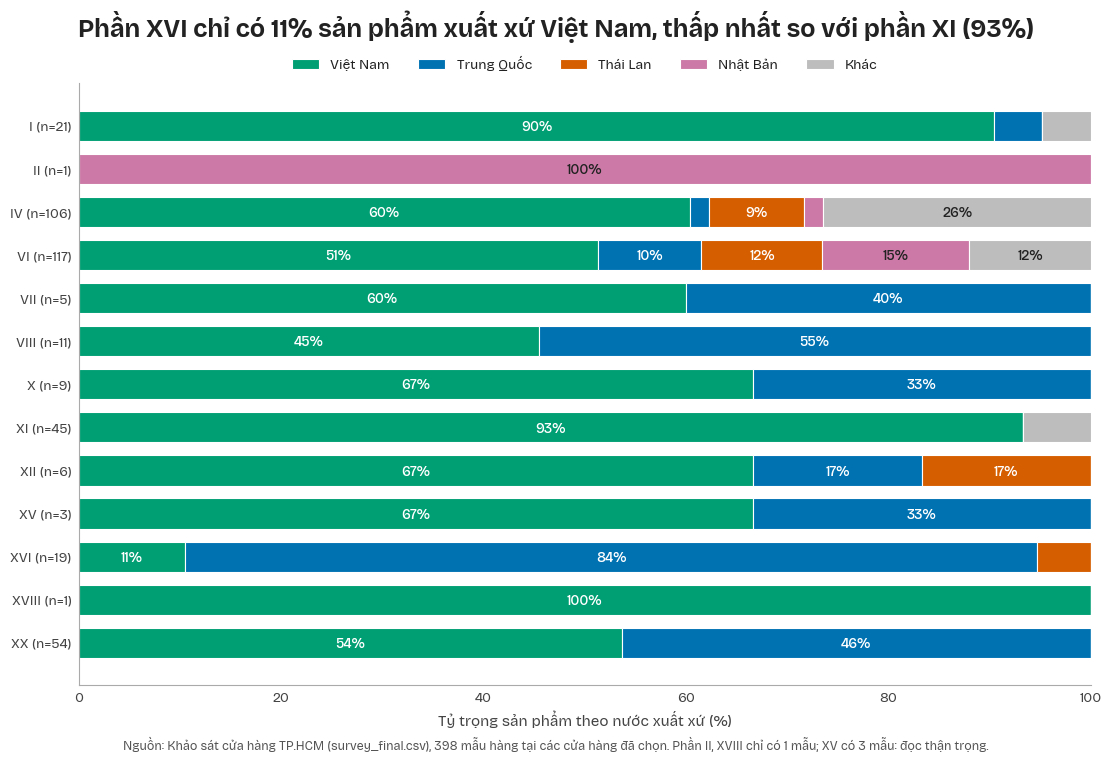

In [14]:
# ===== C06A =====
df_c06a = df.dropna(subset=["hs2022_section", "origin_country"]).copy()
top3_c06a = df_c06a.loc[df_c06a.origin_country != VN, "origin_country"].value_counts().head(3).index.tolist()
df_c06a["nhom_xx"] = np.where(df_c06a.origin_country.isin([VN] + top3_c06a), df_c06a.origin_country, "Khác")

nhom_order = [VN] + top3_c06a + ["Khác"]
iso = {"Trung Quốc": "CHN", "Thái Lan": "THA", "Nhật Bản": "JPN", "Hàn Quốc": "KOR", "Mỹ": "USA"}
col_c06a = {VN: VN_COLOR, "Khác": OTHER_COLOR}
col_c06a.update({c: PARTNER_COLORS[iso[c]] for c in top3_c06a})   # màu cố định theo house_style

hs_c06a = [s for s in HS_ORDER if s in set(df_c06a.hs2022_section)]
ct = pd.crosstab(df_c06a.hs2022_section, df_c06a.nhom_xx).reindex(index=hs_c06a, columns=nhom_order, fill_value=0)
n_c06a = ct.sum(axis=1)
pct_c06a = ct.div(n_c06a, axis=0) * 100
print(top3_c06a); display(pct_c06a.round(1).assign(n=n_c06a))

# Action title (tính từ dữ liệu): phần HS có n >= 10 với tỷ trọng VN thấp nhất
cand = pct_c06a[VN][n_c06a >= 10]
lo, hi = cand.idxmin(), cand.idxmax()
title_c06a = (f"Phần {lo} chỉ có {cand[lo]:.0f}% sản phẩm xuất xứ Việt Nam, "
              f"thấp nhất so với phần {hi} ({cand[hi]:.0f}%)")

with apply_style():
    fig_c06a, ax_c06a = plt.subplots(figsize=(11, 7.5), layout="constrained")
    y = np.arange(len(hs_c06a))
    left = np.zeros(len(hs_c06a))
    for g in nhom_order:
        w = pct_c06a[g].values
        ax_c06a.barh(y, w, left=left, color=col_c06a[g], label=g, height=0.7, edgecolor="white", linewidth=0.8)
        for yi, (l, wi) in enumerate(zip(left, w)):
            if wi >= 7:
                ax_c06a.text(l + wi/2, yi, f"{wi:.0f}%", ha="center", va="center", color=text_color(col_c06a[g]), **DIRECT_LABEL)
        left += w
    ax_c06a.set_yticks(y, [hs_label(s, n_c06a[s]) for s in hs_c06a])
    ax_c06a.invert_yaxis()                      # I ở trên cùng
    ax_c06a.set_xlim(0, 100)
    ax_c06a.set_xlabel("Tỷ trọng sản phẩm theo nước xuất xứ (%)")
    declutter(ax_c06a, "x")
    ax_c06a.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig_c06a.suptitle(title_c06a)
    fig_c06a.supxlabel(NGUON + ". Phần II, XVIII chỉ có 1 mẫu; XV có 3 mẫu: đọc thận trọng.", **SOURCE)
    fig_c06a.savefig(OUT / "C06A_co_cau_xuat_xu_theo_hs.png", dpi=300)
    plt.show()

## C06B – Tỷ trọng hàng Việt theo mức giá
- **Task (Q4.2):** *So sánh* tỷ trọng hàng Made in Vietnam *theo mức giá*.
- **Dạng:** 100% stacked horizontal bar (Thấp / Trung bình / Cao + thanh riêng cho mẫu chưa phân loại).
- **Lý do:** chồng 100% so VN / ngoài VN giữa ba nhóm giá.
- **Xử lý:** dùng `price_tier` đã phân theo danh mục và đơn vị so sánh giá (không tự đặt ngưỡng); mẫu thiếu tier ghi riêng, không gộp vào ba nhóm.

,n,vn,pct_vn,pct_ngoai
tier,,,,
Thấp,119,88,73.9,26.1
Trung bình,93,61,65.6,34.4
Cao,94,44,46.8,53.2
Chưa phân loại,92,44,47.8,52.2


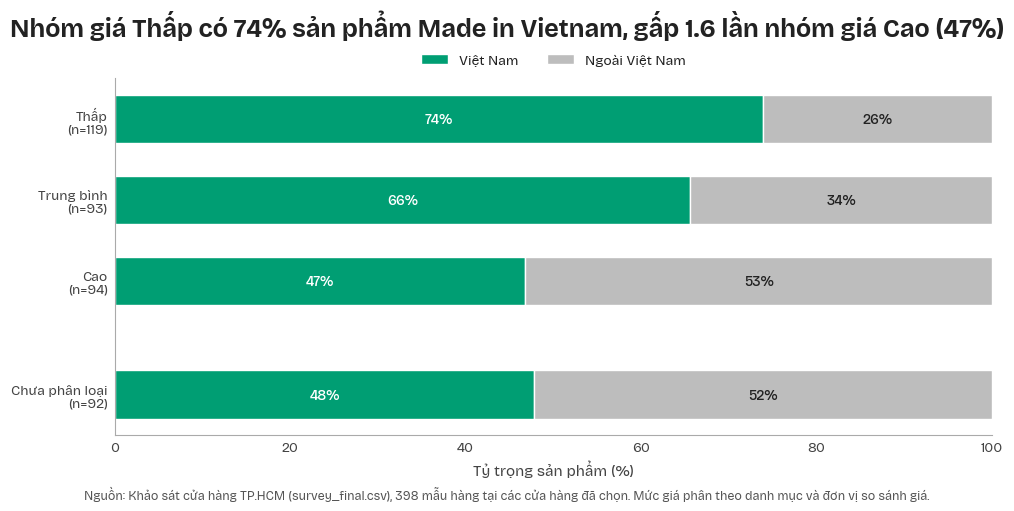

In [15]:
# ===== C06B =====
df_c06b = df.dropna(subset=["origin_country"]).copy()
tiers = ["Thấp", "Trung bình", "Cao"]
df_c06b["tier"] = df_c06b.price_tier.where(df_c06b.price_tier.isin(tiers), "Chưa phân loại")
rows = tiers + ["Chưa phân loại"]
g_c06b = df_c06b.groupby("tier").made_in_vietnam.agg(n="size", vn="sum").reindex(rows)
g_c06b["pct_vn"] = g_c06b.vn / g_c06b.n * 100
g_c06b["pct_ngoai"] = 100 - g_c06b.pct_vn
display(g_c06b.round(1))

hi_t, lo_t = g_c06b.loc[tiers, "pct_vn"].idxmax(), g_c06b.loc[tiers, "pct_vn"].idxmin()
title_c06b = (f"Nhóm giá {hi_t} có {g_c06b.pct_vn[hi_t]:.0f}% sản phẩm Made in Vietnam, "
              f"gấp {g_c06b.pct_vn[hi_t]/g_c06b.pct_vn[lo_t]:.1f} lần nhóm giá {lo_t} ({g_c06b.pct_vn[lo_t]:.0f}%)")

with apply_style():
    fig_c06b, ax_c06b = plt.subplots(figsize=(10, 5), layout="constrained")
    ypos = np.array([0, 1, 2, 3.4])              # khoảng cách tách thanh "Chưa phân loại"
    for lab, col, key in [("Việt Nam", VN_COLOR, "pct_vn"), ("Ngoài Việt Nam", OTHER_COLOR, "pct_ngoai")]:
        left = g_c06b.pct_vn.values if key == "pct_ngoai" else 0
        ax_c06b.barh(ypos, g_c06b[key], left=left, color=col, label=lab, height=0.6, edgecolor="white")
        for yi, v, l in zip(ypos, g_c06b[key], np.atleast_1d(left) if key == "pct_ngoai" else np.zeros(4)):
            ax_c06b.text(l + v/2, yi, f"{v:.0f}%", ha="center", va="center", color=text_color(col), **DIRECT_LABEL)
    ax_c06b.set_yticks(ypos, [f"{r}\n(n={int(g_c06b.n[r])})" for r in rows])
    ax_c06b.invert_yaxis()
    ax_c06b.set_xlim(0, 100)
    ax_c06b.set_xlabel("Tỷ trọng sản phẩm (%)")
    declutter(ax_c06b, "x")
    ax_c06b.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig_c06b.suptitle(title_c06b)
    fig_c06b.supxlabel(NGUON + ". Mức giá phân theo danh mục và đơn vị so sánh giá.", **SOURCE)
    fig_c06b.savefig(OUT / "C06B_ty_trong_hang_viet_theo_muc_gia.png", dpi=300)
    plt.show()

## C06C – Mức tập trung xuất xứ (CR3) theo phần HS
- **Task (Q4.3):** *Tính / so sánh* mức tập trung ba nước xuất xứ hàng đầu (CR3) *theo phần HS*.
- **Dạng:** lollipop (mỗi phần HS một chấm 0–100%), xếp I → XX theo yêu cầu nhóm.
- **Lý do:** lollipop so thứ tự tập trung gọn, ít mực hơn cột.
- **Xử lý:** trong mỗi phần HS lấy 3 nước nhiều sản phẩm nhất; CR3 = tổng sản phẩm 3 nước / tổng sản phẩm biết xuất xứ × 100. Phần có ≤ 3 nước thì CR3 = 100% hiển nhiên → chấm rỗng.

,n,n_nuoc,cr3,top3
hs,,,,
I,21,3,100.0,"Việt Nam, Trung Quốc, Canada"
II,1,1,100.0,Nhật Bản
IV,106,14,77.4,"Việt Nam, Thái Lan, Hàn Quốc"
VI,117,12,77.8,"Việt Nam, Nhật Bản, Thái Lan"
VII,5,2,100.0,"Việt Nam, Trung Quốc"
VIII,11,2,100.0,"Trung Quốc, Việt Nam"
X,9,2,100.0,"Việt Nam, Trung Quốc"
XI,45,2,100.0,"Việt Nam, Campuchia"
XII,6,3,100.0,"Việt Nam, Trung Quốc, Thái Lan"


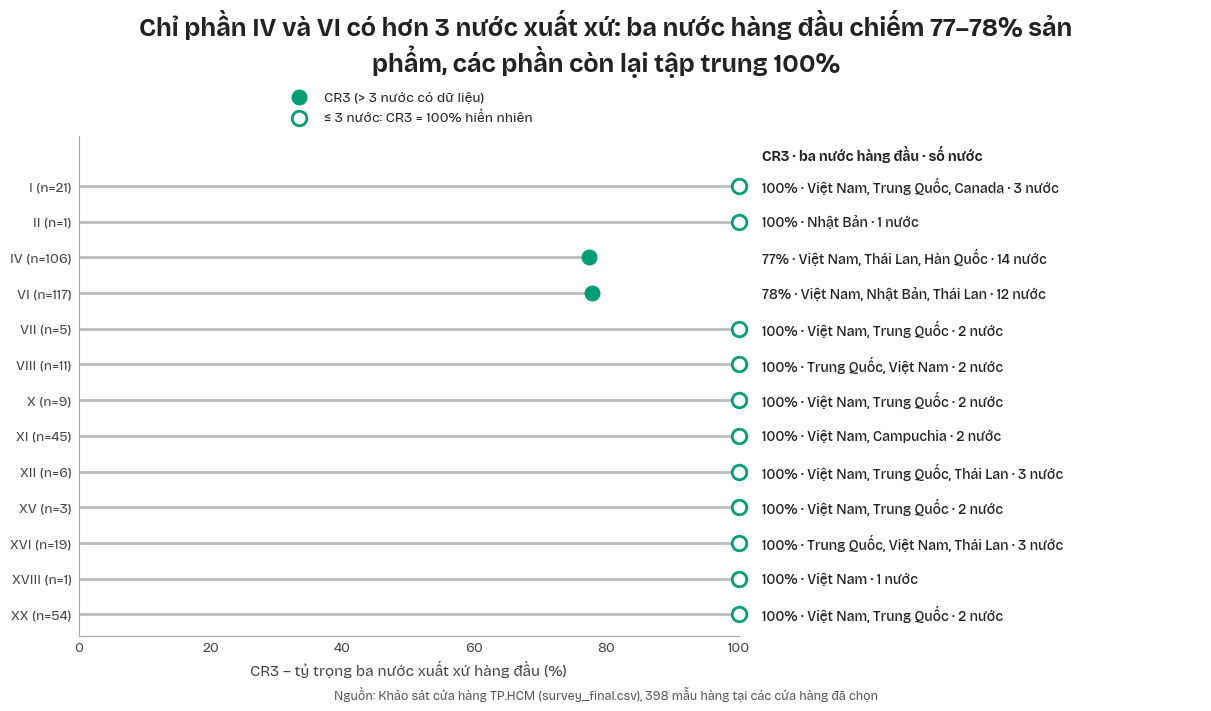

In [16]:
# ===== C06C =====
df_c06c = df.dropna(subset=["hs2022_section", "origin_country"]).copy()
rec = []
for s in [s for s in HS_ORDER if s in set(df_c06c.hs2022_section)]:
    vc = df_c06c.loc[df_c06c.hs2022_section == s, "origin_country"].value_counts()
    rec.append(dict(hs=s, n=vc.sum(), n_nuoc=len(vc), cr3=vc.head(3).sum() / vc.sum() * 100,
                    top3=", ".join(vc.head(3).index)))
cr3_c06c = pd.DataFrame(rec).set_index("hs")
display(cr3_c06c.round(1))

cand = cr3_c06c[(cr3_c06c.n >= 10) & (cr3_c06c.n_nuoc > 3)]      # phần đủ mẫu và > 3 nước
ten = " và ".join(cand.index)
title_c06c = textwrap.fill(
    f"Chỉ phần {ten} có hơn 3 nước xuất xứ: ba nước hàng đầu chiếm {cand.cr3.min():.0f}–{cand.cr3.max():.0f}% sản phẩm, "
    f"các phần còn lại tập trung 100%", 75)

with apply_style():
    fig_c06c, (ax_c06c, ax_txt) = plt.subplots(1, 2, figsize=(12, 7), sharey=True,
                                               width_ratios=[3, 2], layout="constrained")
    y = np.arange(len(cr3_c06c))
    ax_c06c.hlines(y, 0, cr3_c06c.cr3, color=OTHER_COLOR, linewidth=2)
    full = (cr3_c06c.n_nuoc > 3).values
    ax_c06c.scatter(cr3_c06c.cr3[full], y[full], s=110, color=VN_COLOR, zorder=3, clip_on=False, label="CR3 (> 3 nước có dữ liệu)")
    ax_c06c.scatter(cr3_c06c.cr3[~full], y[~full], s=110, facecolor="white", edgecolor=VN_COLOR,
                    linewidth=2, zorder=3, clip_on=False, label="≤ 3 nước: CR3 = 100% hiển nhiên")
    ax_txt.axis("off")
    ax_txt.text(0.0, -0.9, "CR3 · ba nước hàng đầu · số nước", va="center", ha="left", fontweight="bold", **{k: v for k, v in DIRECT_LABEL.items() if k != "fontweight"})
    for yi, (s, r) in zip(y, cr3_c06c.iterrows()):
        ax_txt.text(0.0, yi, f"{r.cr3:.0f}% · {r.top3} · {int(r.n_nuoc)} nước", va="center", ha="left", **DIRECT_LABEL)
    ax_c06c.set_yticks(y, [hs_label(s, int(r.n)) for s, r in cr3_c06c.iterrows()])
    ax_c06c.set_ylim(len(y) - 0.4, -1.4)                  # I ở trên cùng, chừa chỗ tiêu đề cột
    ax_c06c.set_xlim(0, 100)
    ax_c06c.set_xlabel("CR3 – tỷ trọng ba nước xuất xứ hàng đầu (%)")
    declutter(ax_c06c, "x")
    ax_c06c.legend(ncol=1, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig_c06c.suptitle(title_c06c)
    fig_c06c.supxlabel(NGUON, **SOURCE)
    fig_c06c.savefig(OUT / "C06C_cr3_theo_hs.png", dpi=300)
    plt.show()

## Kiểm tra trước khi bàn giao
- 14 mẫu `verify_status = Cần xác minh` vẫn nằm trong biểu đồ (xuất xứ đã có giá trị), cần ghi chú khi báo cáo.
- Phần HS có n quá nhỏ (II, XVIII = 1; XV = 3) chỉ mang tính minh họa.

In [10]:
print("Action title:")
for t in (title_c06a, title_c06b, title_c06c): print("-", t)
print("Số mẫu cần xác minh trong từng biểu đồ:",
      (df_c06a.verify_status != "OK").sum(), (df_c06b.verify_status != "OK").sum(), (df_c06c.verify_status != "OK").sum())

Action title:
- Phần XVI chỉ có 11% sản phẩm xuất xứ Việt Nam, thấp nhất so với phần XI (93%)
- Nhóm giá Thấp có 74% sản phẩm Made in Vietnam, gấp 1.6 lần nhóm giá Cao (47%)
- Chỉ phần IV và VI có hơn 3 nước xuất xứ: ba nước hàng đầu chiếm 77–78% sản
phẩm, các phần còn lại tập trung 100%
Số mẫu cần xác minh trong từng biểu đồ: 14 14 14
